#  Mushroom Classification: Edible or Poisonous?

Models compared: **Decision Tree** vs **K-Nearest Neighbors (KNN)**

## 1. The Idea
**What does the model predict?** Given physical features of a mushroom (cap shape, odor, gill size, spore-print colour, etc.), the model predicts whether it is **edible** or **poisonous**.

- Wild mushroom poisoning is a real safety risk, and many poisonous species look like edible ones.
- It shows how machine learning can find patterns (like "odor" being a strong signal) that are hard for beginners to spot.
- It is a classic binary-classification problem, so it is ideal for learning the full ML workflow.

> ⚠️ This is a learning project. **Never** use it to decide whether to eat a real mushroom.

**Dataset:** [UCI Mushroom Dataset](https://archive.ics.uci.edu/dataset/73/mushroom): 8,124 mushrooms, 22 categorical features, target = `class` (`e` = edible, `p` = poisonous).

## 2. Data Preparation

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, LabelEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

RANDOM_STATE = 42

### 2.1 The dataset


In [15]:
columns = [
    "class", "cap-shape", "cap-surface", "cap-color", "bruises", "odor",
    "gill-attachment", "gill-spacing", "gill-size", "gill-color",
    "stalk-shape", "stalk-root", "stalk-surface-above-ring", "stalk-surface-below-ring",
    "stalk-color-above-ring", "stalk-color-below-ring", "veil-type", "veil-color",
    "ring-number", "ring-type", "spore-print-color", "population", "habitat",
]
URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/mushroom/agaricus-lepiota.data"
LOCAL = "mushrooms.csv"   # optional: put a downloaded copy next to the notebook

try:
    df = pd.read_csv(LOCAL, header=None, names=columns)
except FileNotFoundError:
    df = pd.read_csv(URL, header=None, names=columns)

print("Shape:", df.shape)
df.head()

Shape: (8124, 23)


,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


### 2.2 Check for missing values
In this dataset, missing values are written as `?` (not as blank cells), so `isnull()` alone would miss them.

In [16]:
print("Standard NaN count:", df.isnull().sum().sum())

question_marks = (df == "?").sum()
print("\nColumns containing '?':")
print(question_marks[question_marks > 0])

Standard NaN count: 0

Columns containing '?':
stalk-root    2480
dtype: int64


Only `stalk-root` has missing entries. Rather than deleting those rows (which would throw away a lot of data), we keep them and treat `?` as its own category, **"unknown"**. Missing information can itself be a useful signal.

Class balance:
class
e    4208
p    3916
Name: count, dtype: int64


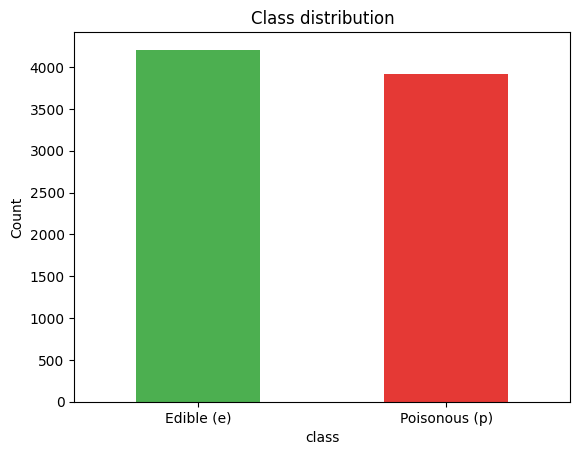

In [17]:
df["stalk-root"] = df["stalk-root"].replace("?", "unknown")

print("Class balance:")
print(df["class"].value_counts())
df["class"].value_counts().plot(kind="bar", color=["#4caf50", "#e53935"])
plt.xticks([0, 1], ["Edible (e)", "Poisonous (p)"], rotation=0)
plt.ylabel("Count"); plt.title("Class distribution"); plt.show()

The classes are nearly balanced, so **accuracy** is a fair metric here.

### 2.3 Features and target
All features are categories (letters), but models need numbers.
- **Target (`y`)**: encode `e → 0`, `p → 1`.
- **Features (`X`)**: use **one-hot encoding** (one 0/1 column per category). We avoid plain label encoding because it would imply a false order between categories, which would mislead KNN's distance calculation.

In [18]:
X_raw = df.drop(columns="class")
y_raw = df["class"]

le = LabelEncoder()
y = le.fit_transform(y_raw)          # e -> 0, p -> 1
print("Classes:", dict(zip(le.classes_, le.transform(le.classes_))))

X = pd.get_dummies(X_raw)            # one-hot encode every feature
print("Features after encoding:", X.shape[1])

Classes: {'e': np.int64(0), 'p': np.int64(1)}
Features after encoding: 117


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (6499, 117)  Test: (1625, 117)


## 3. Model Building

### Model 1: Decision Tree
Learns a flowchart of yes/no questions. We cap `max_depth` at 5 to keep it readable and avoid memorising the data.

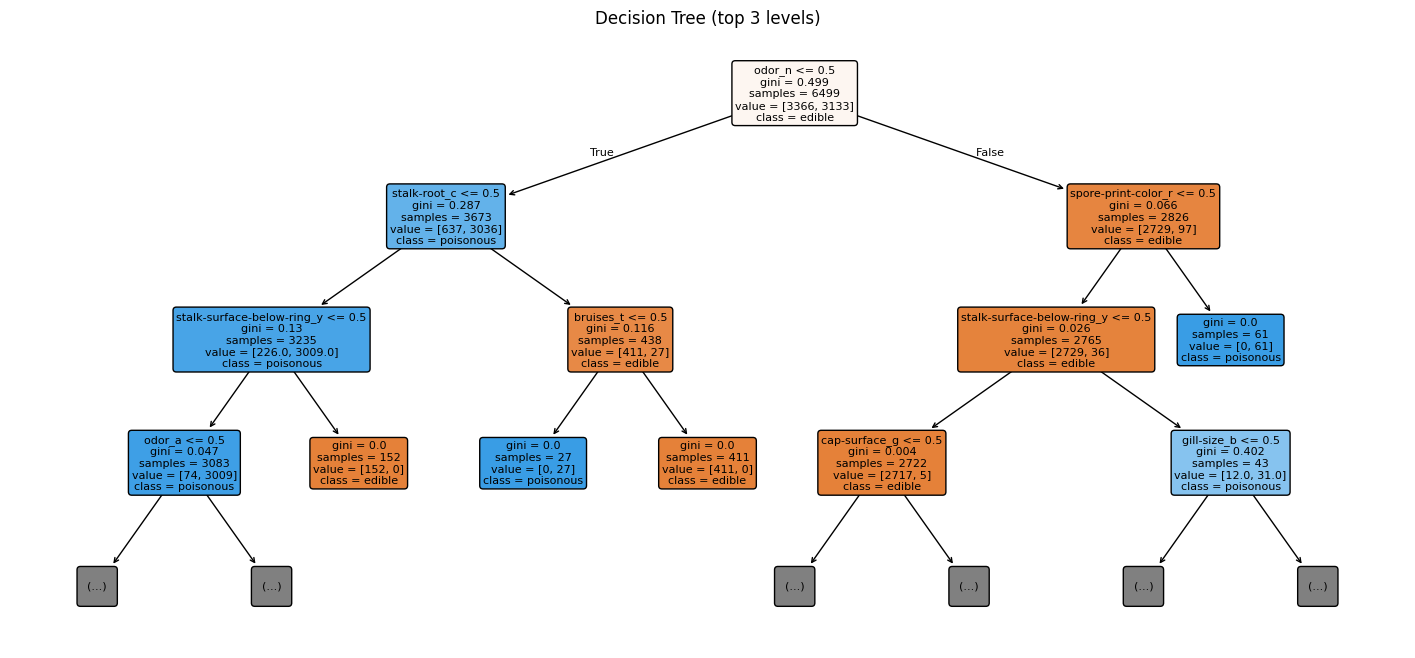

In [7]:
tree = DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE)
tree.fit(X_train, y_train)
tree_pred = tree.predict(X_test)

plt.figure(figsize=(18, 8))
plot_tree(tree, max_depth=3, feature_names=X.columns, class_names=["edible", "poisonous"],
          filled=True, rounded=True, fontsize=8)
plt.title("Decision Tree (top 3 levels)"); plt.show()

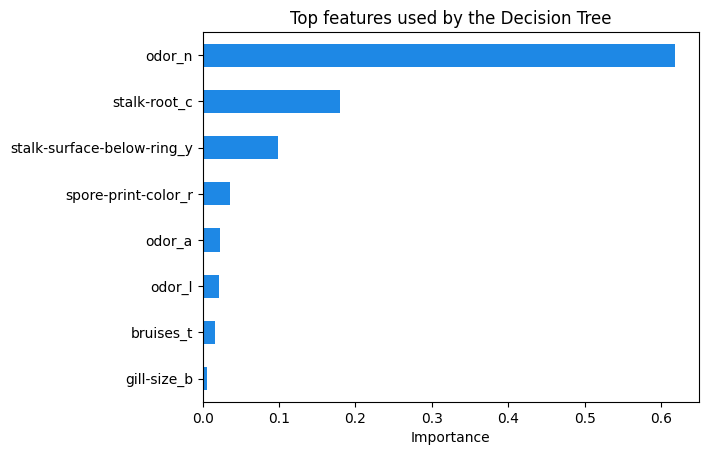

In [8]:
importances = pd.Series(tree.feature_importances_, index=X.columns).sort_values(ascending=False).head(8)
importances.sort_values().plot(kind="barh", color="#1e88e5")
plt.title("Top features used by the Decision Tree"); plt.xlabel("Importance"); plt.show()

### Model 2: K-Nearest Neighbors (KNN)
Classifies a mushroom by looking at its `k` most similar neighbours and taking a majority vote. First we try a few values of `k`.

In [9]:
for k in [1, 3, 5, 7, 9, 11]:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    print(f"k={k:>2}  test accuracy = {accuracy_score(y_test, m.predict(X_test)):.4f}")

k= 1  test accuracy = 1.0000
k= 3  test accuracy = 1.0000
k= 5  test accuracy = 1.0000
k= 7  test accuracy = 1.0000
k= 9  test accuracy = 1.0000
k=11  test accuracy = 0.9988


In [10]:
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)

## 4. Evaluation

In [11]:
results = pd.DataFrame({
    "Model": ["Decision Tree (max_depth=5)", "KNN (k=5)"],
    "Accuracy": [accuracy_score(y_test, tree_pred), accuracy_score(y_test, knn_pred)],
}).set_index("Model")
results["Accuracy"] = results["Accuracy"].round(4)
results

,Accuracy
Model,
Decision Tree (max_depth=5),0.9988
KNN (k=5),1.0000


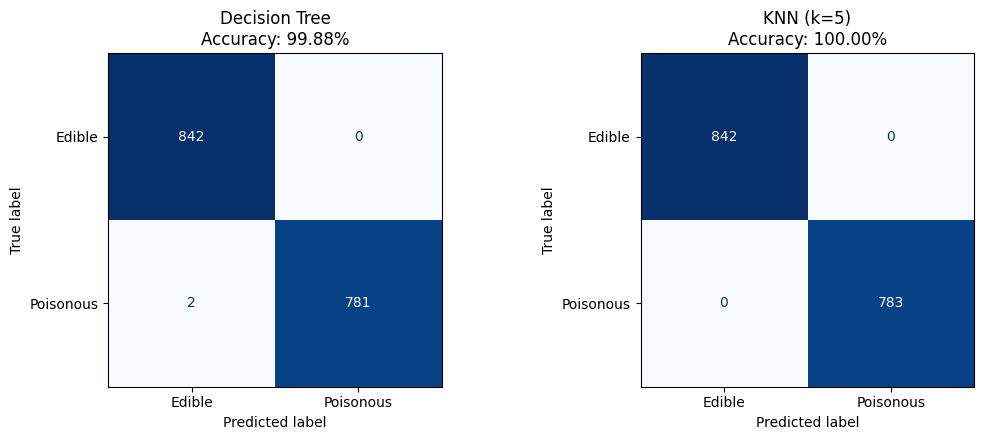

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, pred, name in zip(axes, [tree_pred, knn_pred], ["Decision Tree", "KNN (k=5)"]):
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=["Edible", "Poisonous"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}\nAccuracy: {accuracy_score(y_test, pred):.2%}")
plt.tight_layout(); plt.show()

**Reading the confusion matrix:** the most dangerous mistake is a **false negative for poison**: predicting *edible* for a *poisonous* mushroom (bottom-left cell, row "Poisonous", column "Edible"). Accuracy alone hides this, so we also check precision and recall.

In [13]:
for name, pred in [("Decision Tree", tree_pred), ("KNN", knn_pred)]:
    print(f"=== {name} ===")
    print(classification_report(y_test, pred, target_names=["Edible", "Poisonous"], digits=4))

=== Decision Tree ===
              precision    recall  f1-score   support

      Edible     0.9976    1.0000    0.9988       842
   Poisonous     1.0000    0.9974    0.9987       783

    accuracy                         0.9988      1625
   macro avg     0.9988    0.9987    0.9988      1625
weighted avg     0.9988    0.9988    0.9988      1625

=== KNN ===
              precision    recall  f1-score   support

      Edible     1.0000    1.0000    1.0000       842
   Poisonous     1.0000    1.0000    1.0000       783

    accuracy                         1.0000      1625
   macro avg     1.0000    1.0000    1.0000      1625
weighted avg     1.0000    1.0000    1.0000      1625



## 5. Conclusion
**Which model performed better?** Compare the accuracy table and confusion matrices above. On this dataset both models usually score at or near 100%, because the features (especially `odor`, `spore-print-color` and `gill-size`) separate the classes very clearly. If one is slightly ahead, note by how many test samples, and above all whether it makes any dangerous *poisonous → edible* mistakes.

**Decision Tree vs KNN:**
- The Decision Tree is **easy to explain** (we can see exactly which questions it asks) and fast to predict with.
- KNN needs no training but is **slower at prediction time** and its results depend on the choice of `k` and the encoding.

**What I learned:**
1. Missing values can be hidden behind symbols like `?`, so always inspect the raw data.
2. Categorical features need proper encoding (one-hot) before modelling.
3. Accuracy is not the whole story. The *type* of error matters, especially in safety-critical tasks.
4. A simple, interpretable model can match a more complex one when the data is clean.
5. Very high accuracy can mean the problem is easy, but real-world use would still need expert verification.

**Next steps:** try Random Forest, use cross-validation, and test with fewer features to see how robust the models are.